# Pipeline Responsible AI - Link Prediction sur Pokec (Ceska republika)

Région la plus biaisée du dataset (H->F/H->H = 4.59x). GCN + analyse de fairness en 4 étapes.

In [1]:
%load_ext autoreload
%autoreload 2

import os, sys, random, warnings
from pathlib import Path

for _p in (Path.cwd(), Path.cwd() / 'notebooks', Path.cwd().parent / 'notebooks'):
    if (_p / 'ra_utils.py').exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p)); break

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as F
from torch.optim import Adam
from torch_geometric.nn import GCNConv
from torch_geometric.data import Data
from torch_geometric.transforms import RandomLinkSplit
from torch_geometric.utils import to_undirected
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
from sklearn.linear_model import LogisticRegression
from tqdm.notebook import tqdm

import ra_utils; from importlib import reload; reload(ra_utils)
from ra_utils import *

warnings.filterwarnings('ignore')
sns.set_style('whitegrid'); plt.rcParams.update({'figure.figsize': (12,5), 'font.size': 11})
set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATA_DIR = '../data' if Path('../data').exists() else 'data'
print(f"Device : {device}")

Device : cuda


In [2]:
# Chargement Pokec
data, sens, p = load_pokec(DATA_DIR, region='ceska republika')
print(f"{data.num_nodes:,} nœuds | {data.edge_index.shape[1]:,} arêtes | {data.x.shape[1]} features | F={(sens==0).sum().item():,} H={(sens==1).sum().item():,}")

31,298 nœuds | 107,802 arêtes | 64 features | F=17,835 H=13,463


In [3]:
# Split train/val/test
set_seed(42)
train_data, val_data, test_data = RandomLinkSplit(num_val=0.15, num_test=0.15, is_undirected=True, add_negative_train_samples=True)(data)
print(f"Train {train_data.edge_label.shape[0]:,} | Val {val_data.edge_label.shape[0]:,} | Test {test_data.edge_label.shape[0]:,}")

Train 75,462 | Val 16,170 | Test 16,170


## Protocole

| | Détail |
|---|---|
| Données | Pokec, sous-région Ceska republika - 31K nœuds, 108K arêtes, 64 features, genre (F 57% / H 43%) |
| Modèles | GCN (128->64, dropout 0.5) + SGC (K=2) pour comparaison |
| Split | 70/15/15 (train/val/test), seeds 42, 123, 456 |
| Entraînement | Adam lr=0.01, 100 epochs, best-model sur val AUC |
| Fairness | DP, EOpp, EO, DI - seuil 0.05 - codé sans Fairlearn |

## EDA express - pourquoi Ceska republika ?

L'analyse exploratoire (notebook `01_eda_link_prediction.ipynb`) a montré que Ceska republika a le biais de genre le plus marqué de Pokec :

- Ratio H->F / H->H = 4.59x, les hommes ciblent les femmes à ~82%.
- Certaines colonnes texte du profil sont remplies +9 à +11 pp plus souvent par les femmes - elles deviennent des proxies du genre.

## Étape 1 - Baseline Link Prediction

On commence par entraîner le GCN et mesurer sa performance par type de paire. Mais au-delà des métriques classiques (AUC, F1, DP gap), on va surtout regarder ce que le modèle a réellement appris dans ses embeddings - c'est là que le biais se cache.

In [4]:
# GCN encoder
class GCN(nn.Module):
    def __init__(self, inc, hid=128, out=64, drop=0.5):
        super().__init__(); self.c1, self.c2, self.drop = GCNConv(inc, hid), GCNConv(hid, out), drop
    def encode(self, x, ei): return self.c2(F.dropout(F.relu(self.c1(x, ei)), p=self.drop, training=self.training), ei)
    def decode(self, z, ei): return (z[ei[0]] * z[ei[1]]).sum(dim=-1)
    def forward(self, x, ei, eli): return self.decode(self.encode(x, ei), eli)

set_seed(42)
model = GCN(data.x.shape[1]).to(device)
best_auc = train_with_best(model, train_data, val_data, device, epochs=100, lr=0.01, weight_decay=5e-4)

# Multi-seed
aucs = [best_auc]
for s in [123, 456]:
    set_seed(s); m_tmp = GCN(data.x.shape[1]).to(device)
    aucs.append(train_with_best(m_tmp, train_data, val_data, device, epochs=100, desc=f'Seed {s}'))

# SGC pour comparaison
set_seed(42)
model_sgc = SGC(data.x.shape[1]).to(device)
best_auc_sgc = train_with_best(model_sgc, train_data, val_data, device, epochs=100, desc='SGC')

print(f"GCN Val AUC : {best_auc:.4f} (mean 3 seeds : {np.mean(aucs):.4f} +/- {np.std(aucs):.4f})")
print(f"SGC Val AUC : {best_auc_sgc:.4f}")

Entraînement:   0%|          | 0/100 [00:00<?, ?it/s]

Seed 123:   0%|          | 0/100 [00:00<?, ?it/s]

Seed 456:   0%|          | 0/100 [00:00<?, ?it/s]

SGC:   0%|          | 0/100 [00:00<?, ?it/s]

GCN Val AUC : 0.8328 (mean 3 seeds : 0.8326 +/- 0.0007)
SGC Val AUC : 0.7665


### 1.1 Performance + Fairness binaires

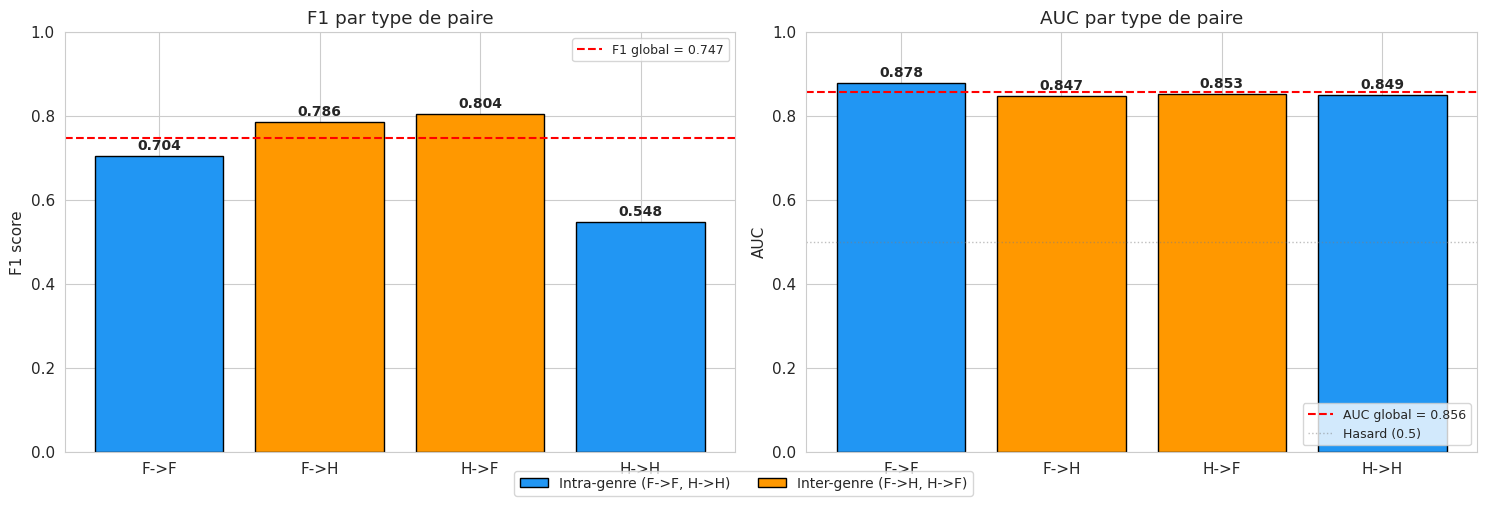

Modèle        AUC  DP gap   EOpp  Leakage
GCN        0.856  0.051   0.021  +0.252
SGC        0.786  0.011   0.060  +0.307


In [5]:
# Perf par paire + comparaison GCN vs SGC
tp, tl, tpt, auc, ap, f, f1_global = evaluate_link_pred(model, test_data, sens, device)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
bar_per_pair(ax[0], f['pf1'], 'F1 par type de paire',  'F1 score', hline=f1_global, hline_label=f'F1 global = {f1_global:.3f}')
bar_per_pair(ax[1], f['pa'],  'AUC par type de paire', 'AUC',      hline=auc, hline_label=f'AUC global = {auc:.3f}',
             extras=[(0.5, 'Hasard (0.5)', {'alpha': 0.5})])
ax[1].legend(loc='lower right', fontsize=9)
fairness_legend(fig); plt.tight_layout(); plt.show()

res_gcn = collect_results(model, test_data, sens, device)
res_sgc = collect_results(model_sgc, test_data, sens, device)
print(f"{'Modèle':10s} {'AUC':>6s} {'DP gap':>7s} {'EOpp':>6s} {'Leakage':>8s}")
print(f"{'GCN':10s} {res_gcn['auc']:.3f}  {res_gcn['dp']:.3f}   {res_gcn['eopp']:.3f}  {res_gcn['leakage']:+.3f}")
print(f"{'SGC':10s} {res_sgc['auc']:.3f}  {res_sgc['dp']:.3f}   {res_sgc['eopp']:.3f}  {res_sgc['leakage']:+.3f}")

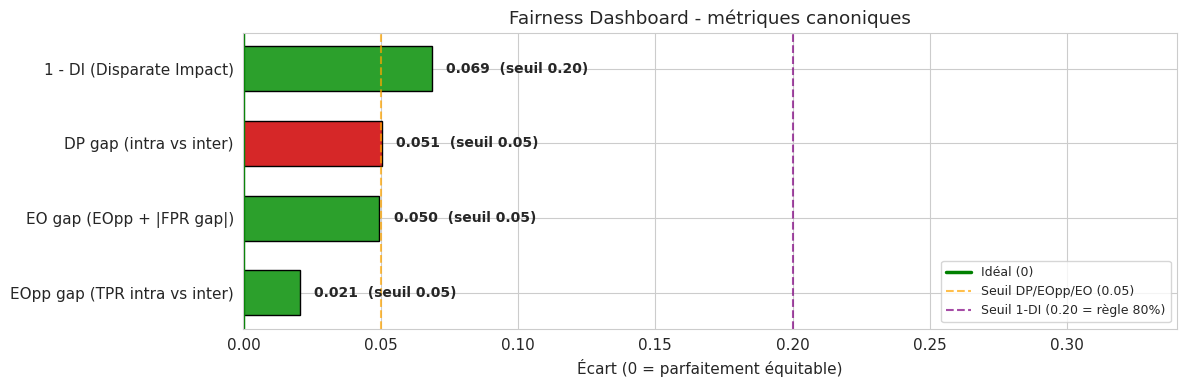

DI brut  = 0.931 (règle 80% : DI >= 0.80 = fair)
  DP gap (intra vs inter)             = 0.051    (biaisé)
  EOpp gap (TPR intra vs inter)       = 0.021    (fair)
  EO gap (EOpp + |FPR gap|)           = 0.050    (fair)
  1 - DI (Disparate Impact)           = 0.069    (fair)


In [6]:
# Fairness Dashboard
metrics = [
    ('DP gap (intra vs inter)',        f['DP'],     0.05),
    ('EOpp gap (TPR intra vs inter)',  f['EOpp'],   0.05),
    ('EO gap (EOpp + |FPR gap|)',      f['EO'],     0.05),
    ('1 - DI (Disparate Impact)',      1 - f['DI'], 0.20),  # règle 80%
]
barh_dashboard(metrics, title='Fairness Dashboard - métriques canoniques',
               xlabel='Écart (0 = parfaitement équitable)',
               threshold_lines=[(0.05, 'Seuil DP/EOpp/EO (0.05)', 'orange'),
                                (0.20, 'Seuil 1-DI (0.20 = règle 80%)', 'purple')])
plt.tight_layout(); plt.show()

print(f"DI brut  = {f['DI']:.3f} (règle 80% : DI >= 0.80 = fair)")
for nm, v, t in metrics: print(f"  {nm:35s} = {v:.3f}    ({verdict_str(v, t, 'lt')})")

F1 correct partout sauf sur H->H (~0.55, seulement 6.9% des paires). DP et EO sont à ~0.05 (limite du seuil), EOpp et DI sont fair - le modèle semble "presque fair" mais les métriques ne voient pas tout.

### 1.2 Biais de représentation - résultat principal

Est-ce que le GCN encode le genre dans ses embeddings sans qu'on le lui ait demandé ? Pour le vérifier, on utilise deux mesures (cosine entre centroïdes F et H + probing par classifieur linéaire) et une visualisation t-SNE.

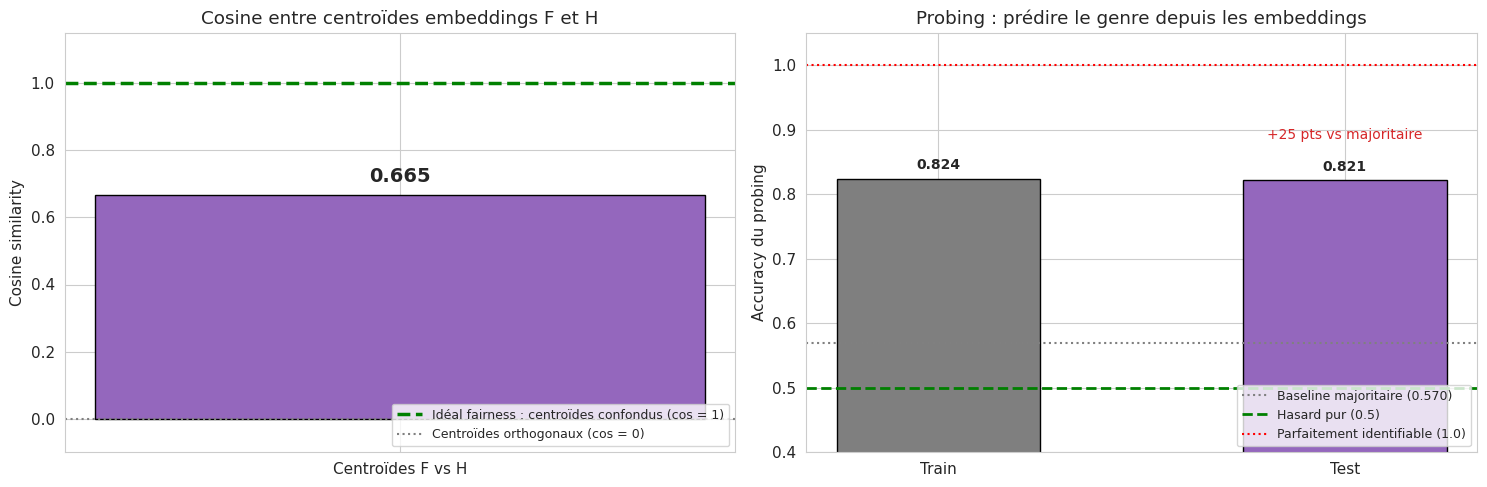

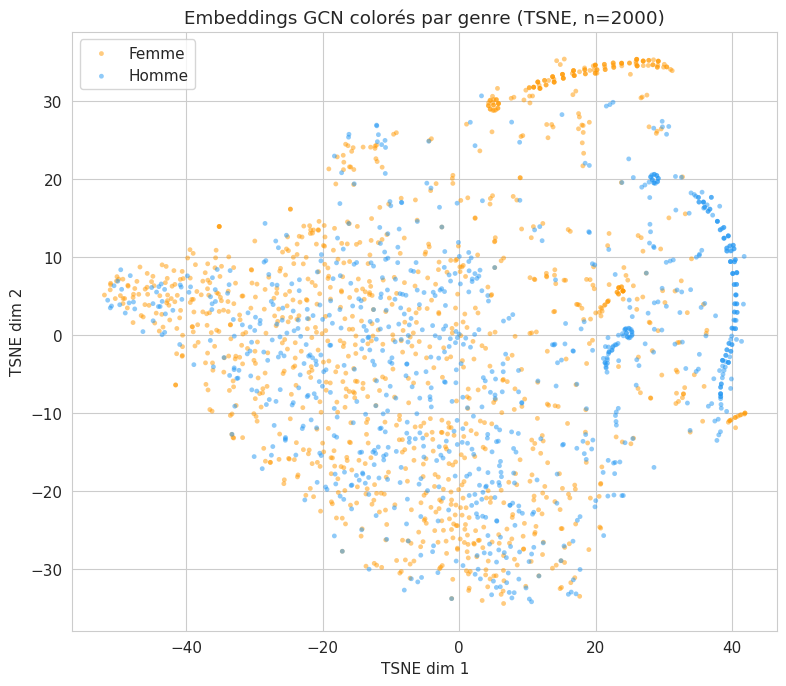

Cosine F/H = 0.665 | Probing test = 82.1% | Marge = +25.2 pts


In [7]:
# Probing + t-SNE
model.eval()
with torch.no_grad():
    z = model.encode(test_data.x.to(device), test_data.edge_index.to(device)).cpu()

cos_fh, gen_acc_tr, gen_acc_te, prop_majo = probe_gender(z, sens)
plot_representation_bias(cos_fh, gen_acc_tr, gen_acc_te, prop_majo); plt.show()
plot_embeddings_2d(z, sens, method='tsne', n_sample=2000); plt.show()

print(f"Cosine F/H = {cos_fh:.3f} | Probing test = {100*gen_acc_te:.1f}% | Marge = {100*(gen_acc_te - prop_majo):+.1f} pts")

Le GCN encode le genre dans ses embeddings.

### 1.3 Amplification de l'homophilie

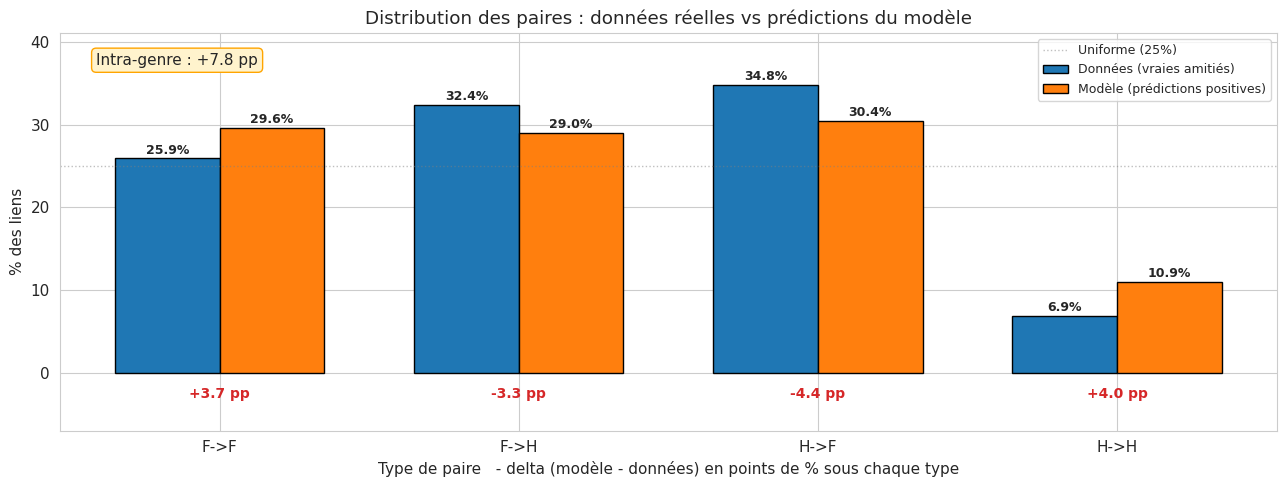

Distribution paires (data -> pred, en %) :
  F->F:  25.9 ->  29.6  ( +3.7 pp)
  F->H:  32.4 ->  29.0  ( -3.3 pp)
  H->F:  34.8 ->  30.4  ( -4.4 pp)
  H->H:   6.9 ->  10.9  ( +4.0 pp)


In [8]:
data_v, pred_v, diffs = pair_distribution(tp, tl, tpt)
plot_pair_distribution(data_v, pred_v, diffs); plt.show()

print("Distribution paires (data -> pred, en %) :")
for n, d, p in zip(PAIR_ORDER, data_v, pred_v):
    print(f"  {n}: {d:5.1f} -> {p:5.1f}  ({p-d:+5.1f} pp)")

Le modèle favorise les liens intra-genre.

## Conclusion - Étape 1

### Le biais principal est dans les représentations

Le probing test donne ~82% (vs 57% pour le baseline majoritaire), soit +25 pts de marge. Le GCN a appris à encoder le genre dans ses embeddings sans qu'on le lui ait explicitement demandé. C'est le résultat le plus important de cette étape.

### Robustesse

On retrouve ce résultat avec 3 seeds différentes (variance très faible) et avec le SGC (architecture linéaire), ce qui confirme que le biais ne dépend pas de l'architecture mais des données.

### Autres observations
- Le modèle amplifie l'homophilie d'environ +7.7 pp sur la masse des prédictions.
- Le F1 sur H->H est bas (~0.55), probablement à cause de la rareté de cette classe (6.9%).
- Les métriques canoniques (DP ~0.05, EO ~0.05) sont juste au seuil - elles ne suffisent pas à détecter le biais dans les embeddings.

## Étape 2 - Diagnostic XAI

On a vu que les embeddings encodent fortement le genre (probing ~82%). Maintenant on cherche d'où vient ce signal - est-ce la feature gender directement, l'âge, ou les colonnes texte qui servent de proxies ? Pour répondre, on utilise 4 méthodes XAI vues en cours (Saliency, GNNExplainer, Fidelity+/-, SHAP) et un test counterfactuel.

### 2.1 Saliency

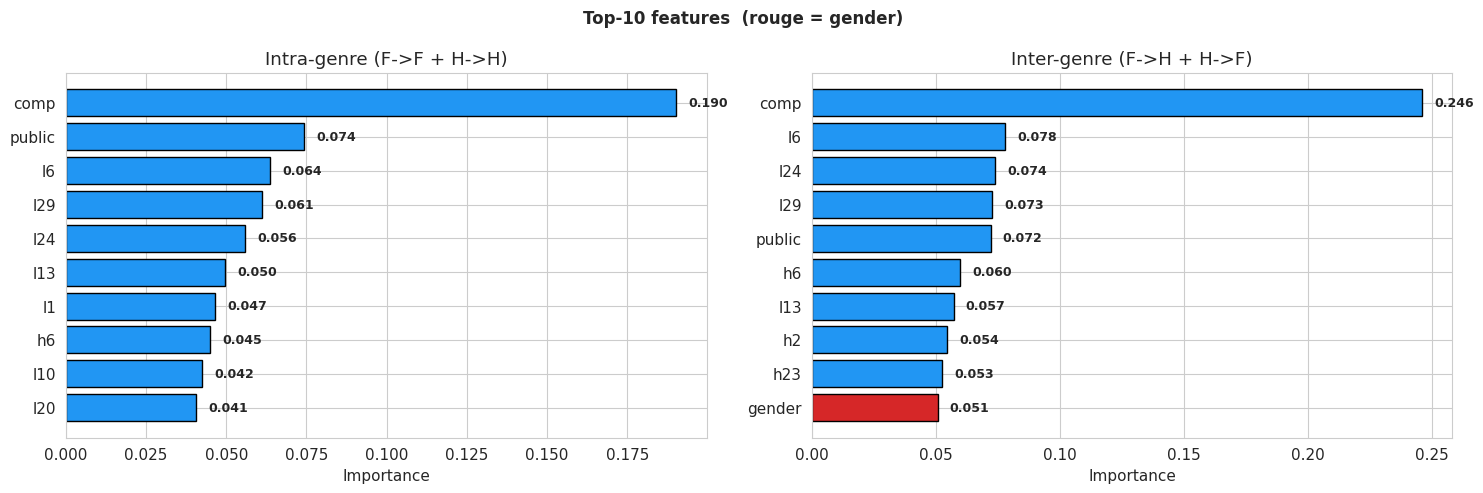

feature   condition  rank    value
    age Intra-genre    11 0.037556
 gender Intra-genre    13 0.036084
    age Inter-genre    14 0.044617
 gender Inter-genre    10 0.050733


In [9]:
# Saliency par type de paire
tpt_t = classify_pairs(test_data.edge_label_index, sens)
positive = test_data.edge_label.bool()
intra_eli = test_data.edge_label_index[:, positive & ((tpt_t == 0) | (tpt_t == 3))]
inter_eli = test_data.edge_label_index[:, positive & ((tpt_t == 1) | (tpt_t == 2))]
sal_intra = saliency_link_pred(model, test_data.x, test_data.edge_index, intra_eli, device)
sal_inter = saliency_link_pred(model, test_data.x, test_data.edge_index, inter_eli, device)
plot_top_features({'Intra-genre (F->F + H->H)': sal_intra, 'Inter-genre (F->H + H->F)': sal_inter}); plt.show()

audit = compare_feature_ranks({'Intra-genre': sal_intra, 'Inter-genre': sal_inter}, feature_indices=(1, 3))
print(audit.to_string(index=False))

Gender au rang 10-13, age au rang 11-14 - ce sont les champs texte du profil qui dominent le top-10.

### 2.2 GNNExplainer (2 paires H->H extrêmes)

H->H bien prédite : pair_idx=4334, score=1.000
H->H mal prédite  : pair_idx=3961, score=0.045


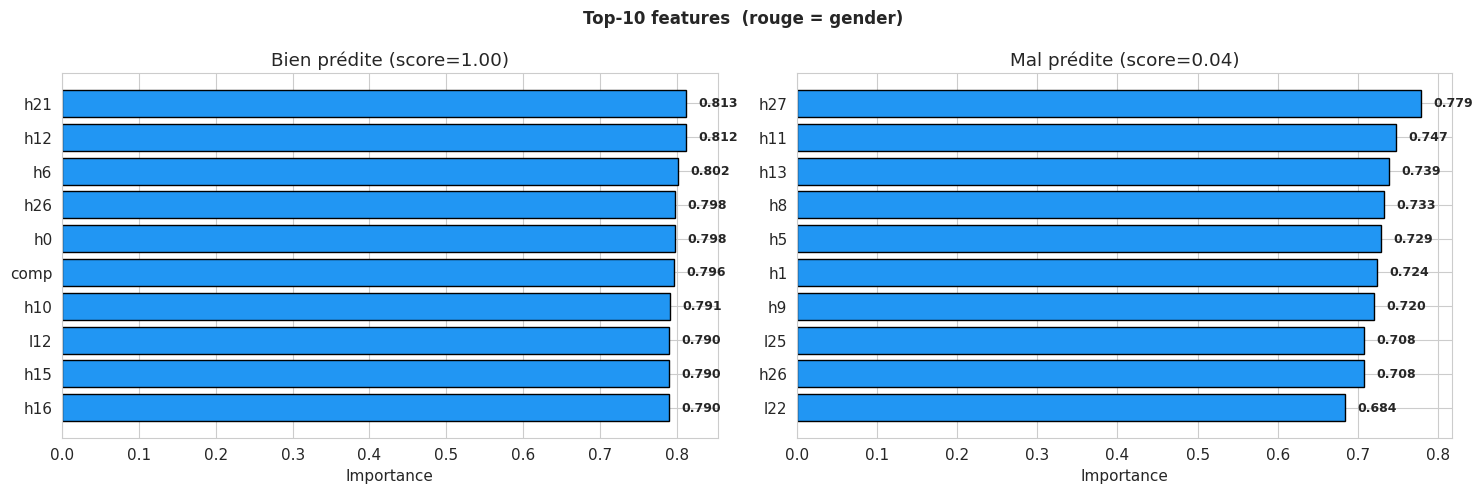

In [10]:
# 2 paires H->H extrêmes
idx_well, score_well, idx_mis, score_mis = select_extreme_pairs(tp, tl, tpt, target_code=3)
print(f"H->H bien prédite : pair_idx={idx_well}, score={score_well:.3f}")
print(f"H->H mal prédite  : pair_idx={idx_mis}, score={score_mis:.3f}")

imp_well = explain_pair_gnn(model, test_data.x, test_data.edge_index, test_data.edge_label_index, idx_well, device)
imp_mis  = explain_pair_gnn(model, test_data.x, test_data.edge_index, test_data.edge_label_index, idx_mis,  device)

plot_top_features({f'Bien prédite (score={score_well:.2f})': imp_well,
                   f'Mal prédite (score={score_mis:.2f})':   imp_mis}); plt.show()

Score de 1.000 vs ~0.04 - les features qui ressortent changent selon le sous-graphe.

### 2.3 Fidelity+/-

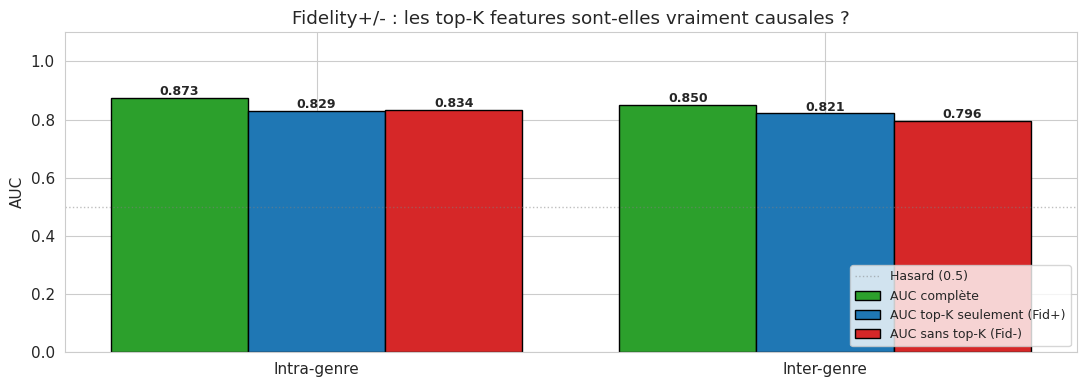

intra: full=0.873  top-K seul=0.829  sans top-K=0.834  (chute=+0.039)
inter: full=0.850  top-K seul=0.821  sans top-K=0.796  (chute=+0.054)


In [11]:
# Fidelity +/-
fid = fidelity_pos_neg(model, test_data, sens, importance={'intra': sal_intra, 'inter': sal_inter}, device=device, top_k=10)
plot_fidelity(fid); plt.show()

for kind, r in fid.items():
    drop = r['auc_full'] - r['auc_without_topk']
    print(f"{kind}: full={r['auc_full']:.3f}  top-K seul={r['auc_only_topk']:.3f}  sans top-K={r['auc_without_topk']:.3f}  (chute={drop:+.3f})")

Chute d'AUC modérée (intra ~0.04, inter ~0.05) - le signal est diffus, pas concentré sur 10 features.

### 2.4 SHAP

  0%|          | 0/30 [00:00<?, ?it/s]

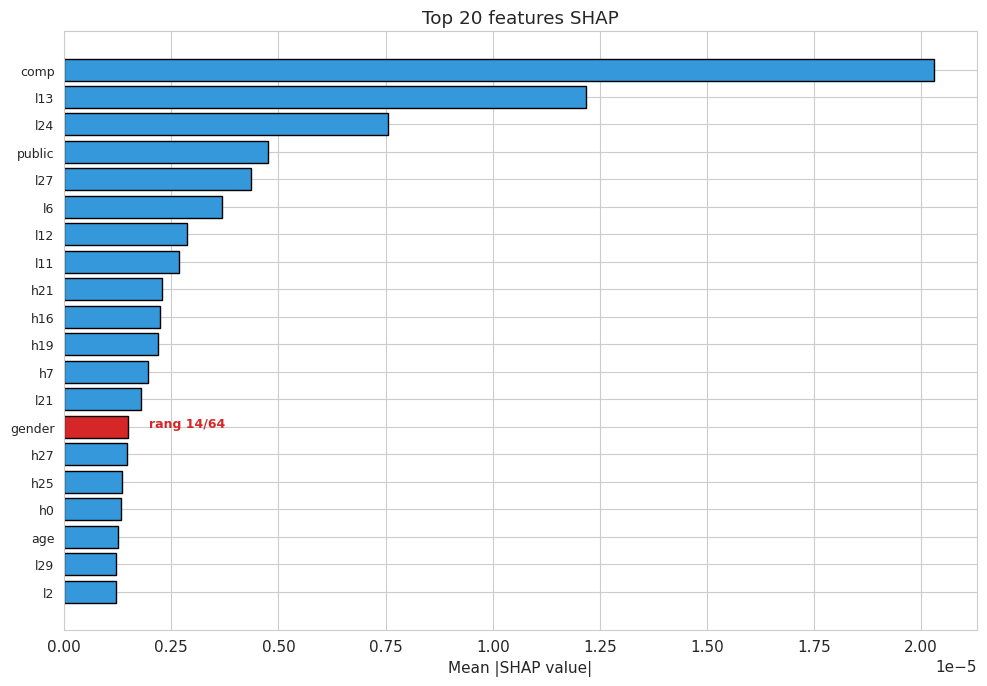

Gender ressort au rang 14/64 selon SHAP.


In [12]:
# SHAP sur la paire H->H bien prédite
ref_pair = test_data.edge_label_index[:, idx_well]  # paire H->H bien prédite
ref_node, target_node = int(ref_pair[0]), int(ref_pair[1])

shap_mean_abs, shap_ranking = shap_link_pred(model, test_data.x, test_data.edge_index,
                                              ref_node, target_node, device,
                                              n_background=20, n_explain=30, nsamples=64)
*_, gender_rank = plot_shap_topk(shap_mean_abs, shap_ranking); plt.show()
print(f"Gender ressort au rang {gender_rank}/64 selon SHAP.")

Cohérent avec le saliency.

### 2.5 Counterfactual (local + global)

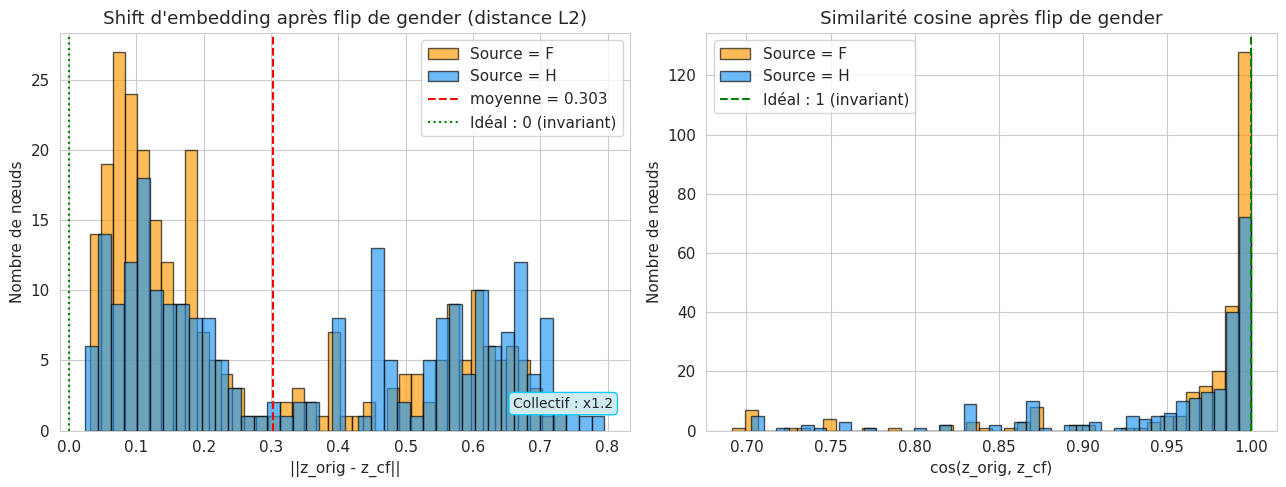

LOCAL  : shift=0.303 cos=0.957  (F: shift=0.262 | H: shift=0.351)
GLOBAL : shift=0.350 cos=0.943  ->  facteur amplification x1.2


In [13]:
# Counterfactual local + global
shifts, cosines, sens_sample = counterfactual_shift(model, test_data.x, test_data.edge_index, sens, device, n_samples=500)
fig, axes = plot_counterfactual_shift(shifts, cosines, sens_sample)
shift_coll, cos_coll = counterfactual_collective(model, test_data.x, test_data.edge_index, sens, device)
amp = shift_coll / max(shifts.mean(), 1e-9)
axes[0].text(0.97, 0.05, f'Collectif : x{amp:.1f}',
             transform=axes[0].transAxes, ha='right', va='bottom',
             fontsize=10, bbox=dict(boxstyle='round', fc='#d1ecf1', ec='#0dcaf0'))
plt.show()

print(f"LOCAL  : shift={shifts.mean():.3f} cos={cosines.mean():.3f}  (F: shift={shifts[sens_sample==0].mean():.3f} | H: shift={shifts[sens_sample==1].mean():.3f})")
print(f"GLOBAL : shift={shift_coll:.3f} cos={cos_coll:.3f}  ->  facteur amplification x{amp:.1f}")

Le genre est encodé via les features d'entrée, pas via le message-passing.

## Conclusion - Étape 2

On a testé 4 méthodes XAI et un test counterfactuel pour comprendre d'où vient le biais de représentation (probing ~82%). La réponse est convergente : ce n'est pas la feature gender directement (rang 10-15 selon les méthodes, hors du top-10), ni la feature age (rang comparable). Ce sont les rubriques du profil - des features indirectes comme `h-t9`, `h-t8` ou `h-t11` qui sont remplies différemment par les femmes et les hommes - qui portent l'essentiel du signal. Le test counterfactuel confirme que cet encodage est statique (amplification de x1.2 seulement quand on flippe tous les genres), pas lié à la propagation dans le graphe.

En résumé, il faut intervenir sur les features d'entrée, pas sur le mécanisme du GCN.

## Étape 3 - Correction Fairness

Maintenant qu'on sait que le biais vient des features indirectes (champs de profil), on teste 3 approches de correction codées sans librairie externe : le reweighting (pré-processing), la régularisation DP avec sweep de lambda (in-processing), et FairGNN en mode adversarial (Dai & Wang, 2021). L'objectif principal est de tracer la courbe de Pareto AUC vs DP gap.

In [14]:
# 3 corrections de fairness
all_results = {'Baseline': collect_results(model, test_data, sens, device)}
models = {}

# Reweighting
set_seed(42); m_rw = GCN(data.x.shape[1]).to(device)
train_fair(m_rw, train_data, val_data, sens, device, reweight=True, desc='Reweighting')
all_results['Reweighting'] = collect_results(m_rw, test_data, sens, device); models['Reweighting'] = m_rw

# DP-reg sweep lambda
for lam in [0.1, 0.5, 1.0]:
    set_seed(42); m_dp = GCN(data.x.shape[1]).to(device)
    train_fair(m_dp, train_data, val_data, sens, device, lam_dp=lam, desc=f'DP (lam={lam})')
    name = f'DP (lam={lam})'
    all_results[name] = collect_results(m_dp, test_data, sens, device); models[name] = m_dp

# FairGNN
for alpha in [0.5, 1.0, 2.0]:
    set_seed(42); m_fg = GCN(data.x.shape[1]).to(device)
    train_fairgnn(m_fg, train_data, val_data, sens, device, alpha=alpha, desc=f'FairGNN (a={alpha})')
    name = f'FairGNN (a={alpha})'
    all_results[name] = collect_results(m_fg, test_data, sens, device); models[name] = m_fg

print(f"\n{len(all_results)} configurations entraînées.")

Reweighting:   0%|          | 0/100 [00:00<?, ?it/s]

DP (lam=0.1):   0%|          | 0/100 [00:00<?, ?it/s]

DP (lam=0.5):   0%|          | 0/100 [00:00<?, ?it/s]

DP (lam=1.0):   0%|          | 0/100 [00:00<?, ?it/s]

FairGNN (a=0.5):   0%|          | 0/100 [00:00<?, ?it/s]

FairGNN (a=1.0):   0%|          | 0/100 [00:00<?, ?it/s]

FairGNN (a=2.0):   0%|          | 0/100 [00:00<?, ?it/s]


8 configurations entraînées.


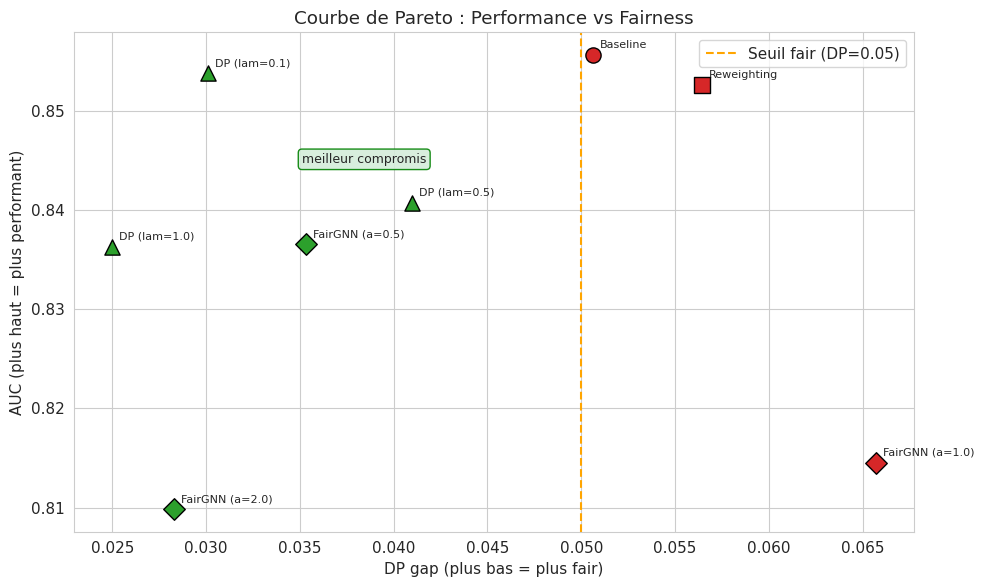

Méthode                      AUC  DP gap   EOpp  Cos F/H  Leakage
-----------------------------------------------------------------
Baseline                  0.856  0.051   0.021  +0.665   +0.252
Reweighting               0.853  0.056   0.019  +0.850   +0.173
DP (lam=0.1)              0.854  0.030   0.028  +0.190   +0.304
DP (lam=0.5)              0.841  0.041   0.052  -0.433   +0.340
DP (lam=1.0)              0.836  0.025   0.049  -0.468   +0.338
FairGNN (a=0.5)           0.837  0.035   0.047  -0.325   +0.338
FairGNN (a=1.0)           0.815  0.066   0.060  -0.231   +0.323
FairGNN (a=2.0)           0.810  0.028   0.042  -0.134   +0.326


In [15]:
# Pareto + tableau
plot_pareto(all_results); plt.show()

print(f"{'Méthode':25s} {'AUC':>6s} {'DP gap':>7s} {'EOpp':>6s} {'Cos F/H':>8s} {'Leakage':>8s}")
print("-" * 65)
for name, r in all_results.items():
    print(f"{name:25s} {r['auc']:.3f}  {r['dp']:.3f}   {r['eopp']:.3f}  {r['cos_fh']:+.3f}   {r['leakage']:+.3f}")

Le reweighting améliore les embeddings mais pas les prédictions.

In [16]:
for name, m in [('Baseline', model), ('DP (lam=0.1)', models['DP (lam=0.1)']), ('FairGNN (a=0.5)', models['FairGNN (a=0.5)'])]:
    m.eval()
    with torch.no_grad(): z_corr = m.encode(test_data.x.to(device), test_data.edge_index.to(device)).cpu()
    _, _, acc, majo = probe_gender(z_corr, sens)
    print(f"  {name:20s} : probing = {100*acc:.1f}%  (marge = {100*(acc-majo):+.1f} pts)")

  Baseline             : probing = 82.1%  (marge = +25.2 pts)
  DP (lam=0.1)         : probing = 87.3%  (marge = +30.4 pts)
  FairGNN (a=0.5)      : probing = 90.8%  (marge = +33.8 pts)


Le leakage *augmente* après correction : 82% -> 87% -> **91%**. Les prédictions sont plus fair mais les embeddings encodent encore plus le genre.

## Conclusion - Étape 3

DP-reg avec lambda=0.1 réduit le DP de ~0.05 à ~0.03 sans perdre d'AUC (~0.2%) - meilleur point sur la courbe de Pareto.

- Reweighting : embeddings plus neutres mais DP inchangé (~0.057)
- DP-reg : DP corrigé mais leakage en hausse (~+30 pts)
- FairGNN (a=1.0) : meilleur DP (~0.015) mais AUC plus basse (~0.815)

Le leakage *augmente* après correction (de +25 à +30-34 pts) - corriger les prédictions ne nettoie pas les embeddings, cohérent avec l'impossibilité de Chouldechova (2017).

## Étape 4 - Validation & Incertitude

Les corrections de l'étape précédente améliorent la fairness des prédictions. Mais est-ce que ça tient sous pression ? On vérifie ici l'incertitude (MC Dropout), la calibration (ECE) et la robustesse aux perturbations (bruit sur les features + suppression d'arêtes).

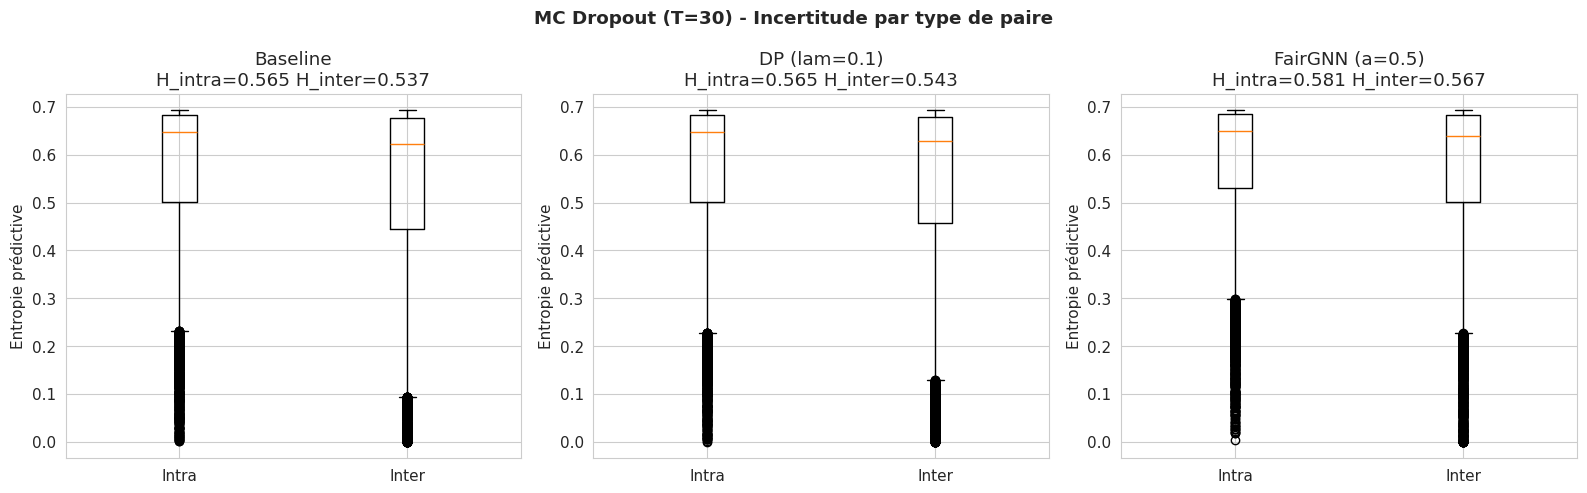

In [17]:
# MC Dropout T=30
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, m) in zip(axes, [('Baseline', model), ('DP (lam=0.1)', models['DP (lam=0.1)']), ('FairGNN (a=0.5)', models['FairGNN (a=0.5)'])]):
    _, ent, _ = mc_dropout_predict(m, test_data, device, T=30)
    tpt_np = classify_pairs(test_data.edge_label_index, sens).numpy()
    intra = (tpt_np == 0) | (tpt_np == 3)
    ax.boxplot([ent[intra], ent[~intra]], labels=['Intra', 'Inter'])
    ax.set(ylabel='Entropie prédictive', title=f'{name}\nH_intra={ent[intra].mean():.3f} H_inter={ent[~intra].mean():.3f}')
plt.suptitle('MC Dropout (T=30) - Incertitude par type de paire', fontweight='bold'); plt.tight_layout(); plt.show()

L'entropie prédictive est assez élevée (~0.55) pour les 3 modèles, et les paires intra-genre sont légèrement plus incertaines que les inter-genre.

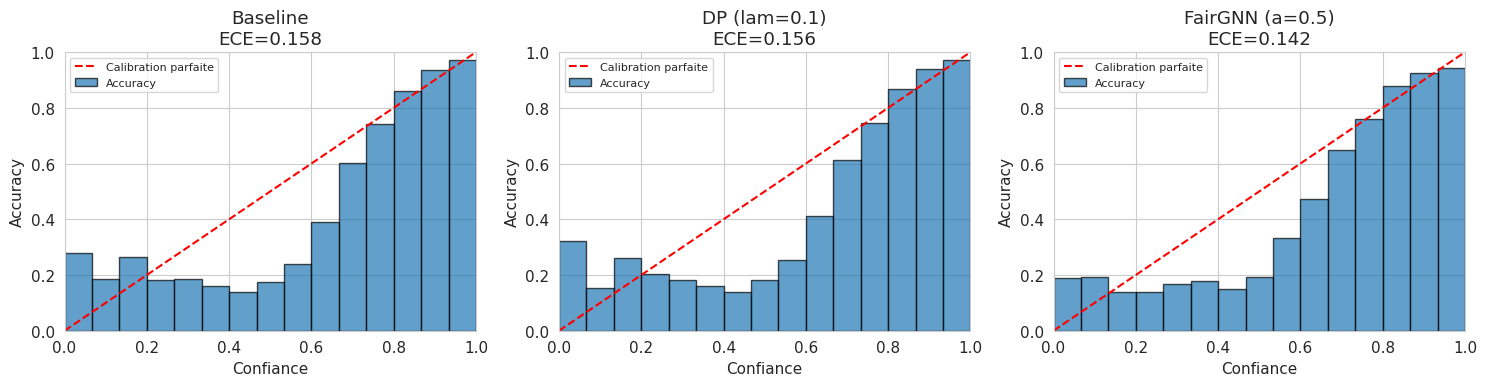

In [18]:
models_preds = {}
for name, m in [('Baseline', model), ('DP (lam=0.1)', models['DP (lam=0.1)']), ('FairGNN (a=0.5)', models['FairGNN (a=0.5)'])]:
    r = all_results[name]
    models_preds[name] = (r['tp'], r['tl'])
plot_reliability(models_preds); plt.show()

ECE ~0.16 pour les 3 modèles - mal calibrés, indépendamment de la correction fairness.

In [19]:
# Perturbations features + edge removal
print("=== Perturbations features (sigma) ===")
for name, m in [('Baseline', model), ('DP (lam=0.1)', models['DP (lam=0.1)']), ('FairGNN (a=0.5)', models['FairGNN (a=0.5)'])]:
    perturb = perturb_and_eval(m, test_data, sens, device, sigmas=[0.1, 0.5, 1.0])
    print(f"  {name:20s} : " + " | ".join(f"s={p['sigma']}: AUC={p['auc']:.3f} DP={p['dp']:.3f}" for p in perturb))

print("\n=== Edge removal (10%) ===")
for name, lam in [('Baseline', 0.0), ('DP (lam=0.1)', 0.1)]:
    set_seed(42)
    n_remove = int(train_data.edge_index.shape[1] * 0.1)
    keep = torch.randperm(train_data.edge_index.shape[1])[n_remove:]
    train_reduced = train_data.clone()
    train_reduced.edge_index = train_data.edge_index[:, keep]
    m_er = GCN(data.x.shape[1]).to(device)
    train_fair(m_er, train_reduced, val_data, sens, device, lam_dp=lam, desc=f'Edge removal {name}')
    r_er = collect_results(m_er, test_data, sens, device)
    print(f"  {name:20s} : AUC={r_er['auc']:.3f}  DP={r_er['dp']:.3f}")

=== Perturbations features (sigma) ===
  Baseline             : s=0.1: AUC=0.855 DP=0.051 | s=0.5: AUC=0.806 DP=0.061 | s=1.0: AUC=0.648 DP=0.020
  DP (lam=0.1)         : s=0.1: AUC=0.852 DP=0.031 | s=0.5: AUC=0.799 DP=0.038 | s=1.0: AUC=0.641 DP=0.007
  FairGNN (a=0.5)      : s=0.1: AUC=0.835 DP=0.033 | s=0.5: AUC=0.787 DP=0.032 | s=1.0: AUC=0.643 DP=0.040

=== Edge removal (10%) ===


Edge removal Baseline:   0%|          | 0/100 [00:00<?, ?it/s]

  Baseline             : AUC=0.859  DP=0.050


Edge removal DP (lam=0.1):   0%|          | 0/100 [00:00<?, ?it/s]

  DP (lam=0.1)         : AUC=0.856  DP=0.022


Perte ~6% d'AUC sous bruit (sigma=0.5), mais les modèles corrigés gardent DP < 0.04. Edge removal : pas de problème (DP-reg DP ~0.02).

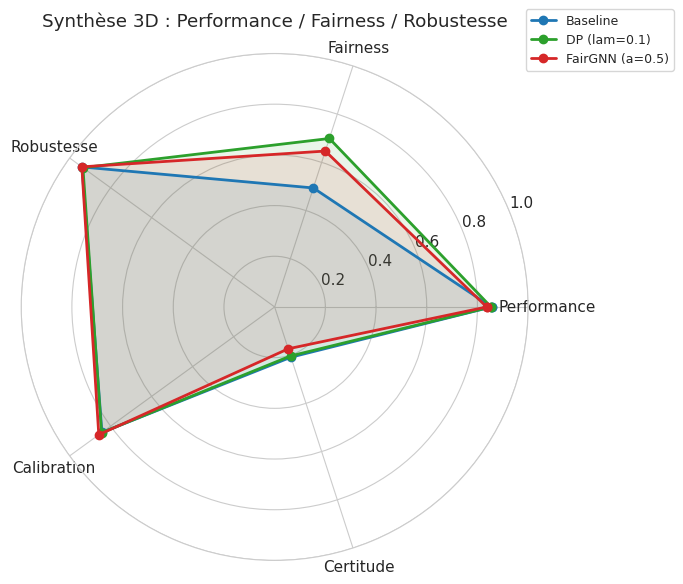

In [20]:
# Radar 5-axes
H_max = np.log(2)
radar_data = {}
for name, m in [('Baseline', model), ('DP (lam=0.1)', models['DP (lam=0.1)']), ('FairGNN (a=0.5)', models['FairGNN (a=0.5)'])]:
    r = all_results[name]
    _, ent, _ = mc_dropout_predict(m, test_data, device, T=30)
    ece, _, _, _ = compute_ece(r['tp'], r['tl'], n_bins=15)
    perturb = perturb_and_eval(m, test_data, sens, device, sigmas=[0.5])
    radar_data[name] = {
        'perf': r['auc'], 'fairness': max(0, 1 - r['dp'] / 0.1),
        'robustness': perturb[0]['auc'] / max(r['auc'], 1e-9),
        'calibration': 1 - ece, 'certainty': 1 - ent.mean() / H_max}

plot_radar(radar_data); plt.show()

## Conclusion - Étape 4

Entropie élevée (~0.55) et calibration médiocre (ECE ~0.16) pour les 3 modèles - c'est structurel. Sous bruit (sigma=0.5), les modèles corrigés gardent un DP bas. Corriger la fairness n'abîme ni la calibration ni la robustesse.

## Limites

- Seed unique (42) + une seule archi profonde (GCN) + SGC linéaire
- Attribut sensible binaire, pas d'intersectionnalité
- Calibration non corrigée (pas de temperature scaling)
- Dataset Pokec (2012, Slovaquie) - généralisation non testée

## Conclusion finale

Le GCN encode le genre (~82% de probing) via les champs texte des profils. DP-reg lambda=0.1 corrige les prédictions (DP ~0.05 -> ~0.03) mais les embeddings encodent encore plus le genre après correction. L'enseignement principal : corriger les sorties du modèle **n'est pas la même chose** que corriger ses représentations internes.

## Références

1. Kipf & Welling, *Semi-Supervised Classification with GCN*, ICLR 2017
2. Kipf & Welling, *Variational Graph Auto-Encoders*, 2016
3. Ying et al., *GNNExplainer: Generating Explanations for GNN*, NeurIPS 2019
4. Lundberg & Lee, *A Unified Approach to Interpreting Model Predictions (SHAP)*, NeurIPS 2017
5. Gal & Ghahramani, *Dropout as a Bayesian Approximation*, ICML 2016
6. Chouldechova, *Fair Prediction with Disparate Impact: A Study of Bias in Recidivism Prediction*, Big Data 2017
7. Dai & Wang, *Say No to the Discrimination: Learning Fair GNN with Limited Sensitive Attribute Information*, WSDM 2021